# Regression models with scikit-learn

## Motivation

In the previous lecture, we studied linear models of the form
$$
y_i = \mu + \mathbf{x}_i'\bm{\beta} + \epsilon_i
$$
where $\mu$ is the intercept (or bias in machine learning lingo), $\mathbf{x}$ is a 
vector of explanatory variables, and $\epsilon_i$ is an additive error
term that captures any residual variance in $y_i$ not accounted for by the explanatory variables.

We estimated the coefficients using ordinary least squares (OLS), which is equivalent to
minimizing the sum of squared errors,
<a id="eq:OLS:loss"></a>
$$
\tag{1}
L(\mu, \bm{\beta}) = 
    \underbrace{\sum_{i=1}^N \Bigl(
    y_i - \mu - \mathbf{x}_i'\bm{\beta}\Bigr)^2}_{\text{Sum of squared errors}}
$$
The estimates $(\widehat{\mu}, \widehat{\bm{\beta}})$ are then the values that minimize $L(\mu, \bm{\beta})$,
$$
(\widehat{\mu}, \widehat{\bm{\beta}}) = \argmin_{\mu,\bm{\beta}} L(\mu, \bm{\beta})
$$

While OLS is the best linear unbiased estimator (BLUE) under the usual assumptions about the errors $\epsilon_i$, the estimated $(\widehat{\mu}, \widehat{\bm{\beta}})$ may not be the best model parameters when it comes to minimizing *out-of-sample* prediction errors. Whenever our focus is on *prediction* rather than on *inference* about population parameters,
we can often do better than using the loss function from [(1)](#eq:OLS:loss).
To this end, we augment the loss function with penalty terms that can reduce overfitting
and improve out-of-sample prediction.

***
## Synthetic sample and polynomial approximation

### Synthetic sample

We use a highly stylized example to study polynomial approximation and overfitting.
We want to approximate a (non-linear) trigonometric function using a high-order
polynomial, a setting that is notoriously susceptible to overfitting (see also the
previous lecture and workshop for illustrations).
Assume that our model is given by
$$
\begin{aligned}
y_i &= \cos\left( \frac{3\pi}{200} x_i \right) + \epsilon_i \\
    \epsilon_i &\stackrel{\text{iid}}{\sim} \mathcal{N}\left(0, 0.5^2\right)
\end{aligned}
$$
where $\epsilon_i$ is an additive, normally distributed measurement error term
with mean $0$ and variance $\frac{1}{4}$. For this exercise, we assume that $x$ is
uniformly distributed on the interval $[0, 100]$.

The true values of $y$ (without measurement error) are computed using the
function `compute_true_y()`, which returns $y$ for a given $x$.

In [1]:
import numpy as np


def compute_true_y(x):
    """
    True trigonometric function (without errors)
    """
    return np.cos(3 * np.pi / 200.0 * x)

The function `create_trig_sample()` defined below is used to generate the training and test samples.

In [2]:
from numpy.random import default_rng


def create_trig_sample(N=100, sigma=0.5, rng=None):
    """
    Create trigonometric relationship sample data.

    Parameters
    ----------
    N : int
        Sample size.
    sigma : float
        Standard deviation of the normal error term.
    rng : np.random.Generator, optional
        Random number generator.
    """

    # Initialize random number generator
    if rng is None:
        rng = default_rng(seed=12345)

    # Randomly draw explanatory variable x uniformly distributed on [0, 100]
    x = rng.uniform(0, 100, size=N)

    # Draw errors from normal distribution
    epsilon = rng.normal(scale=sigma, size=N)

    # Compute y, add measurement error
    y = compute_true_y(x) + epsilon

    return x, y

This lecture uses a training sample with $N=100$ observations and the fixed seed
`12345`. We create `x_train`, `y_train`, and the feature matrix `X_train` once
for all models.

We define `DEGREE = 15` which controls the maximum degree of the polynomial features used in all models in this lecture.
Additionally, we define a common prediction grid, `xvalues`, which we use for plotting the model predictions. 
Its matrix form, `X_grid`, is used as the input for a model's `predict()` method.

In [3]:
# Polynomial degree used throughout the notebook
DEGREE = 15

# Training sample and two-dimensional feature matrix
x_train, y_train = create_trig_sample()
X_train = x_train[:, None]

# Common grid for prediction plots within the training range
xvalues = np.linspace(x_train.min(), x_train.max(), 500)
# Matrix of features used for predict()
X_grid = xvalues[:, None]

The next graph visualizes the true relationship and the sample points $(x_i, y_i)$.
For this purpose, we first define the function `plot_trig_sample()`, which creates the baseline plot used throughout the next few sections.

In [4]:
def plot_trig_sample(x, y):
    """
    Plot the trigonometric relationship and sample.
    """
    import matplotlib.pyplot as plt

    # Sample scatter plot
    _, ax = plt.subplots(figsize=(5.5, 3.5), layout='constrained')
    ax.scatter(x, y, s=20, c='none', edgecolor='steelblue', lw=0.75, label='Sample')

    # Plot true relationship
    x_true = np.linspace(0.0, 100.0, 101)
    y_true = compute_true_y(x_true)
    ax.plot(x_true, y_true, c='black', lw=1.0, label='True function')
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.legend(loc='upper right')

    return ax

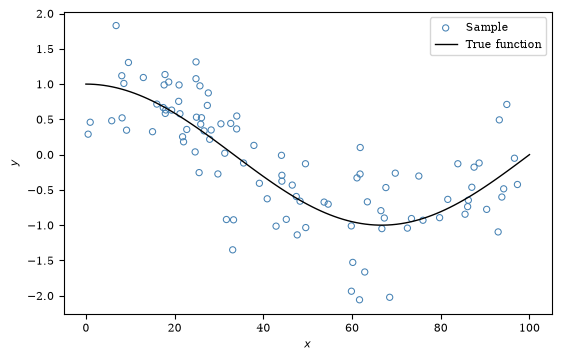

In [5]:
_ = plot_trig_sample(x_train, y_train)

***
### Polynomial approximation

We now estimate a polynomial approximation where we assume that $y$ is a
degree-$K$ polynomial in $x$, i.e.,
$$
y_i \approx \mu + \beta_1 x_i + \beta_2 x_i^2 + \cdots + \beta_K x_i^K
$$
For this example, we choose an unconventionally high $K=15$, set by the constant
`DEGREE`, since we anticipate that this leads to problems with OLS.
These problems are further amplified by the small sample size of $N=100$ observations.
We make these choices for pedagogical reasons so overfitting is visually more apparent.

As in Lecture 2, we use two scaling steps before fitting the model. The complete
pipeline is as follows:

1. We center and scale the original input using
    [`StandardScaler()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
    Writing
    $$
    z_i = \frac{x_i - \bar{x}}{s_x},
    $$
    we subtract the training mean $\bar{x}$ and divide
    by the training standard deviation $s_x$. Centering can reduce correlations between
    powers, while scaling keeps their magnitudes manageable.
2. We then create powers of $z$ with
    [`PolynomialFeatures()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html).
    We use `include_bias=False` because the regression step fits the intercept.
3. A second `StandardScaler()` standardizes the expanded columns. Even when $z$
    has variance one, its powers generally have different variances. This second
    scaler puts them on comparable scales.
4. Finally, we fit a regression model to the transformed features.

The two scalers have different purposes. With our training sample, the correlation
between $x$ and $x^2$ is about 0.972, while the correlation between $z$ and $z^2$
is about 0.383. High powers can still be strongly correlated after input
standardization.

We build a
[`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
that combines these transformations with the estimation step. We use the
[`make_pipeline()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html)
convenience function to simplify this step.

### OLS benchmark

We first estimate the polynomial using ordinary least squares, with
`LinearRegression()` as the final step of the pipeline:

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Create pipeline for linear model
pipe_ols = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    LinearRegression(fit_intercept=True),
)

# Fit model
pipe_ols.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](1,)",[45.35]


We can use the fitted model to predict the outcomes for the fixed grid which we use for plotting the model predictions:

In [7]:
# OLS predictions on the common grid
yhat_grid_ols = pipe_ols.predict(X_grid)

The following cell plots these predicted values together with the true function and the training sample:

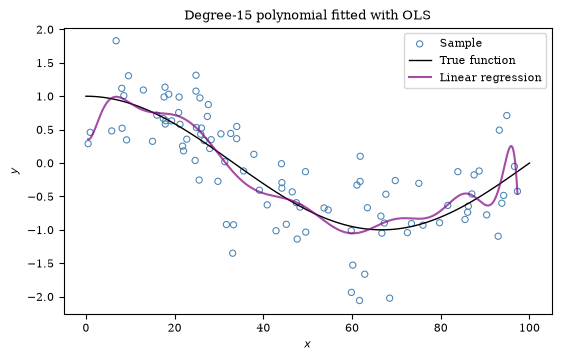

In [8]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# OLS prediction
ax.plot(xvalues, yhat_grid_ols, c='purple', alpha=0.7, label='Linear regression')

ax.set_title(f'Degree-{DEGREE} polynomial fitted with OLS')
_ = ax.legend()

In theory, for OLS with an intercept and a complete polynomial expansion, centering and
scaling leave the fitted polynomial unchanged in exact arithmetic. The estimated
coefficients change to describe the transformed features.
In practice, highly correlated polynomial columns can make the calculations
unstable. The solver may discard nearly dependent directions, changing the
predictions. In our degree-15 example, omitting the input scaler can produce
this kind of numerical truncation even when we standardize the expanded columns.

However, as the figure above shows, more stable calculations
do not prevent overfitting: the fitted polynomial can still follow the noise
in our small sample. We now turn to regularization methods, which address this
problem by explicitly penalizing the coefficients.

***
## Ridge regression

Our first regularized model is Ridge regression, which adds a penalty term to the
OLS loss function:
$$
L(\mu, \bm{\beta}) =
    \underbrace{\sum_{i=1}^N \Bigl(
    y_i - \mu - \mathbf{x}_i'\bm{\beta}\Bigr)^2}_{\text{Sum of squared errors}}
    +
    \underbrace{\alpha \sum_{k=1}^K\beta_k^2}_{\text{L2 penalty}}
$$
Throughout this lecture, we write the objectives using scikit-learn's conventions.
Other formulations are possible, for example using the mean rather than the sum of
squared errors, but this changes the interpretation of the penalty parameter.

Compared to ordinary least squares (OLS), the penalty term increases the loss when
the estimated coefficients $\bm{\beta}$ are large in absolute value.
This term is called an L2 penalty
because it corresponds to the squared L2 vector norm. In many textbooks, we see it
written as $\alpha \|\bm{\beta}\|_2^2$, which is equivalent to the formula above.
For any $\alpha > 0$, the penalty increases with the squared coefficient values.
The estimated coefficients therefore balance fitting the data against keeping their
overall size small. We call this *regularization* or *shrinkage*. The intercept $\mu$
is not included in the penalty term, so it is not directly penalized.

As $\alpha$ approaches zero, the estimates approach the OLS solution.
Conversely, for large $\alpha$, the coefficients approach zero.
Individual coefficients need not decrease
steadily in absolute value, especially when the explanatory variables are highly
correlated. In this setting, $\alpha$ is a hyperparameter, and we can use
cross-validation to select its value.

Why would we use Ridge regression given that OLS is the best linear unbiased
estimator? Regularization can help when we have many, potentially highly correlated,
regressors, in which case OLS is prone to overfitting.

#### Importance of scaling and centering

For Ridge, the second `StandardScaler` after the polynomial expansion puts the expanded features on comparable scales for
the coefficient penalty. High polynomial powers can still be strongly correlated, so input
standardization does not eliminate the need for regularization.

Centering also changes what regularization penalizes. Powers of $x$ and powers
of $z$ can represent the same polynomial functions, but they use different
coefficients. Penalizing these coefficients therefore gives different fitted
models, even after we standardize the expanded columns. While input standardization
can improve numerical stability, it need not improve prediction accuracy.

### Estimating the Ridge model

We use the same preprocessing as in the OLS pipeline, with
[`Ridge()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
as the final step.

To run Ridge regression, we also need to specify the regularization strength
$\alpha$, which we set to $\alpha = 3$ for illustration.

In [9]:
from sklearn.linear_model import Ridge

# Penalty strength to use for Ridge
alpha = 3

# Build pipeline of transformations and Ridge estimation.
# We create the polynomial transformation w/o the intercept so we
# need to include an intercept in the fitting step.
pipe_ridge = make_pipeline(
    StandardScaler(),  # center and scale the original input
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),  # standardize expanded features
    Ridge(alpha=alpha, fit_intercept=True),  # Fit Ridge regression
)

# Fit model
pipe_ridge.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](1,)",[45.35]


We now add the Ridge predictions to the OLS plot to compare the two fitted
polynomials.

In [10]:
# Ridge predictions on the common grid
yhat_grid_ridge = pipe_ridge.predict(X_grid)

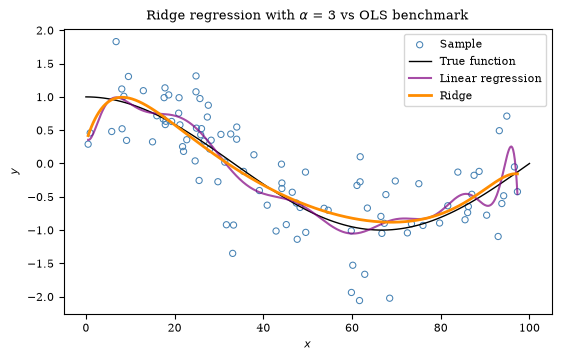

In [11]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Linear regression prediction
ax.plot(xvalues, yhat_grid_ols, c='purple', alpha=0.7, label='Linear regression')

# Ridge prediction
ax.plot(xvalues, yhat_grid_ridge, c='darkorange', lw=2.0, label='Ridge')

ax.set_title(rf'Ridge regression with $\alpha$ = {alpha:.4g} vs OLS benchmark')
_ = ax.legend()

The OLS prediction follows sample fluctuations and oscillates near the right edge of the
training sample. The Ridge prediction is smoother, although it also follows some of the
noise. Later, we will compare prediction errors on new observations to assess how well
the models generalize.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Comment out the first `StandardScaler()` in the Ridge and OLS pipelines above.
   Rerun the fits, predictions, and graph.
2. Restore the first scaler, then comment out the `StandardScaler()` after
   `PolynomialFeatures`. Rerun and inspect the graph again.

How does removing each scaler affect the Ridge predictions relative to OLS?
Why does feature scaling matter when we penalize coefficients?

Restore both scaling steps before continuing.

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Ridge path

To gain some intuition for what is going on, it is instructive to plot the estimated Ridge coefficients for a whole range of $\alpha$ values as we do in the code below. This plot is called the *coefficient path* or *Ridge path* in the context of Ridge regression.

Note that we choose the grid of $\alpha$ to be uniformly spaced on a logarithmic scale since we want to zoom in on what happens when $\alpha$ is small. This is accomplished by using 
[`np.logspace()`](https://numpy.org/doc/stable/reference/generated/numpy.logspace.html)
instead of `np.linspace()`.

We reuse the Ridge pipeline defined above. The
[`set_params()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline.set_params)
method updates its regularization strength through `ridge__alpha`, combining the
step name and parameter name with two underscores. We then refit the pipeline
and recover the fitted coefficients from `named_steps['ridge']`.

Each call to `fit()` also refits the preprocessing steps. Since we use the same
sample for every value of $\alpha$, the transformed features remain the same.

In [12]:
# Create grid of alphas spaced uniformly in logs on [1e-4, 100]
alphas = np.logspace(start=np.log10(1.0e-4), stop=np.log10(100), num=200)

# Array to store one coefficient for each polynomial feature and alpha
coefs = np.empty((len(alphas), DEGREE))

# Reuse the Ridge pipeline, updating alpha before each fit
for i, alpha in enumerate(alphas):
    # Update the penalty in the Ridge step
    pipe_ridge.set_params(ridge__alpha=alpha)

    # Refit the pipeline on the original input
    pipe_ridge.fit(X_train, y_train)

    # Store the coefficients for this alpha
    coefs[i] = pipe_ridge.named_steps['ridge'].coef_

The following plot shows the coefficient on each standardized power of the
centered and scaled input $z$ for different values of $\alpha$. These coefficients
refer to the transformed features, rather than to the original powers of $x$.
The $x$-axis uses a $\log_{10}$ scale so that we can see the behavior at small
values of $\alpha$ more clearly.

We define `plot_coefficient_path()` to draw this plot. The `model_name` argument
lets us reuse the function for both Ridge and Lasso:

In [13]:
def plot_coefficient_path(alphas, coefs, model_name):
    """
    Plot coefficients for different regularization strengths.

    Parameters
    ----------
    alphas : array
        Regularization strengths
    coefs : array
        Coefficients, with one row per strength and one column per feature
    model_name : str
        Model name, either 'Ridge' or 'Lasso'
    """
    import matplotlib.pyplot as plt

    _, ax = plt.subplots(figsize=(6, 4), layout='constrained')
    colors = plt.get_cmap('tab20').colors

    # Use a separate color for each standardized polynomial feature
    for i in range(coefs.shape[1]):
        ax.plot(alphas, coefs[:, i], lw=1.0, c=colors[i], label=rf'$\beta_{{{i + 1}}}$')

    ax.set_xscale('log', base=10)
    ax.axhline(0.0, ls='--', lw=0.75, c='black')
    ax.set_xlabel(r'Regularization strength $\alpha$ (log scale)')
    ax.set_ylabel('Coefficient on standardized feature')
    title = f'{model_name} coefficients as a function of regularization strength'
    ax.set_title(title)
    _ = ax.legend(ncols=5)

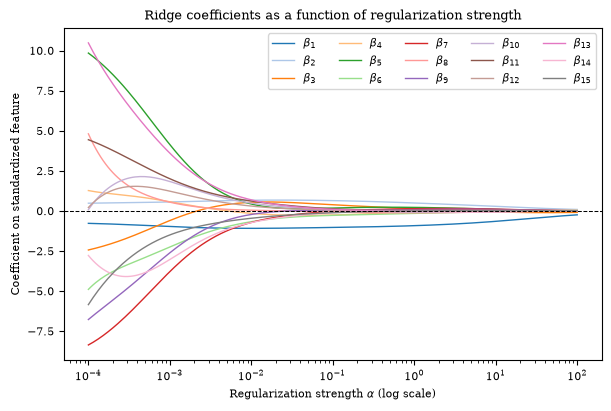

In [14]:
plot_coefficient_path(alphas, coefs, 'Ridge')

The coefficients become smaller overall as $\alpha$ increases, although individual
paths need not move steadily toward zero. At the right endpoint, the coefficients
are substantially smaller but are not exactly zero.
Conversely, as $\alpha$ approaches zero, Ridge approaches OLS.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Find the largest absolute coefficient in the fitted OLS model `pipe_ols`.
   
   *Hint:* The OLS coefficients are stored in the attribute `coef_` in the `'linearregression'` step of the pipeline.

2. Find the largest absolute Ridge coefficient at the left endpoint of the
   path, where the penalty is $\alpha = 10^{-4}$. These coefficients are stored in
   `coefs[0]`.
3. Compare the two values. Does the smallest penalty in our path give
   coefficients close to OLS? What does this tell us about the shrinkage
   produced by a small positive penalty?


</div>
<span style="display: none;">YourTurnEnd</span>

***
### Tuning the regularization parameter via cross-validation

In the previous example, we picked an arbitrary regularization strength $\alpha$.
We now use cross-validation to select it. We search a broad range from
$10^{-4}$ to $10^2$: a narrow range can miss a better minimum elsewhere in the
validation curve (recall from lecture 2 that the validation curve traces the performance of the model as we vary the hyperparameter, here $\alpha$).

Our preprocessing needs to be part of cross-validation. In each split, we estimate
the means and standard deviations for both scalers using only the training observations.
We then apply those same transformations to the validation observations. Scaling the
entire sample before splitting would let information from the validation observations
enter training. This is called *data leakage*.

Scikit-learn provides
[`RidgeCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html),
a class that selects the Ridge regularization strength $\alpha$ by cross-validation.
However, it handles only the regression step. Our example also requires fitting the
scalers separately within each training fold.

We therefore use
[`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
around the complete pipeline. It tries each candidate $\alpha$ and refits both the
preprocessing and the regression model within each training fold.

We define five shuffled folds with
[`KFold()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html)
and fix the random seed so that we can reproduce the splits. We use the same folds
for Lasso and Elastic Net later.

In [15]:
from sklearn.model_selection import GridSearchCV, KFold

# Use the same reproducible splits for all models
cv = KFold(n_splits=5, shuffle=True, random_state=1234)

# Scoring metric for cross-validation
scoring = 'neg_mean_squared_error'

# Candidate regularization strengths on a log scale from 1e-4 to 1e2
ridge_alphas = np.logspace(-4, 2, num=200)

# Keep all preprocessing inside the pipeline
pipe_ridge = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    Ridge(),
)

Once we have set up the CV splitter, the scoring metric, the candidate $\alpha$ values,
and the Ridge pipeline, we create a `GridSearchCV` object and run the cross-validation:

In [16]:
# Define the grid search for Ridge regression with cross-validation
ridge_cv = GridSearchCV(
    pipe_ridge,
    param_grid={'ridge__alpha': ridge_alphas},  # parameters to search over
    scoring=scoring,  # scoring metric for cross-validation
    cv=cv,  # CV splitting strategy
    refit=True,  # refit the best model on the entire training set
    n_jobs=4,  # parallelize over 4 CPU cores
)

# Run the cross-validation
ridge_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge__alpha': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Co

The parameter name `ridge__alpha` combines the pipeline step name
(`ridge`) and its parameter name (`alpha`), separated by two underscores.
The search receives the training inputs `X_train` and target `y_train`, so each
fold gets its own fitted input scaler and expanded-feature scaler.

Scikit-learn's search tools maximize scores. We specify
`scoring='neg_mean_squared_error'` so that maximizing the score minimizes MSE.
The selected parameter is stored in `best_params_`, and the corresponding
average validation score is stored in `best_score_`.

In [17]:
# Recover the selected alpha of the best model
alpha_best = ridge_cv.best_params_['ridge__alpha']

# Average validation MSE of the best model
mse_ridge_cv = -ridge_cv.best_score_

print(f'Best alpha: {alpha_best:.4g}')
print(f'CV MSE: {mse_ridge_cv:.4g}')

Best alpha: 1.351
CV MSE: 0.2489


For our demo sample, the search selects $\alpha \approx 1.351$ with a CV MSE
of about 0.249.

The search also stores results for every candidate in the dictionary
`cv_results_`. We recover each $\alpha$ and its average validation score to plot
the validation curve. These scores are averaged over the five folds.

We define `plot_validation_curve()` to handle these steps for both Ridge and
Lasso. It takes the fitted search and the model name. Converting the name to
lowercase gives the pipeline step name, so the function reads either
`param_ridge__alpha` or `param_lasso__alpha`. Both searches use negative MSE,
which we convert back to MSE for the plot.

In [18]:
def plot_validation_curve(search, model_name):
    """
    Plot validation MSE against alpha and mark the selected value.

    Parameters
    ----------
    search : object
        Fitted GridSearchCV search over the model's alpha
    model_name : str
        Model name, either 'Ridge' or 'Lasso'
    """
    import matplotlib.pyplot as plt

    # Recover candidate alphas, mean validation errors, and the selected index
    param_name = f'param_{model_name.lower()}__alpha'
    alphas = search.cv_results_[param_name]
    mse_mean = -search.cv_results_['mean_test_score']
    imin = search.best_index_

    # Plot the validation curve and highlight the selected alpha
    _, ax = plt.subplots(figsize=(5, 3), layout='constrained')
    ax.plot(alphas, mse_mean)
    ax.scatter(alphas[imin], mse_mean[imin], s=15, c='black', zorder=100)
    ax.axvline(alphas[imin], ls=':', lw=0.75, c='black')
    ax.set_xscale('log')
    ax.set_xlabel(r'Regularization strength $\alpha$ (log scale)')
    ax.set_ylabel('Cross-validated MSE')
    _ = ax.set_title(f'Validation curve for {model_name}')

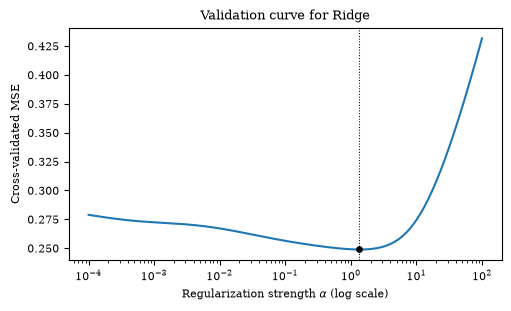

In [19]:
plot_validation_curve(ridge_cv, 'Ridge')

By default, `GridSearchCV` refits the selected pipeline on the entire training
sample after choosing $\alpha$. This fitted pipeline is stored in
`best_estimator_`. We can use it directly to predict from the original $x$
values; the pipeline applies the fitted transformations for us.

In [20]:
# Recover the pipeline already fitted with the selected alpha
pipe_ridge = ridge_cv.best_estimator_

# Compute grid predictions using the selected Ridge model
yhat_grid_ridge = pipe_ridge.predict(X_grid)

Finally, we plot the predicted values together with the training sample and the true relationship:

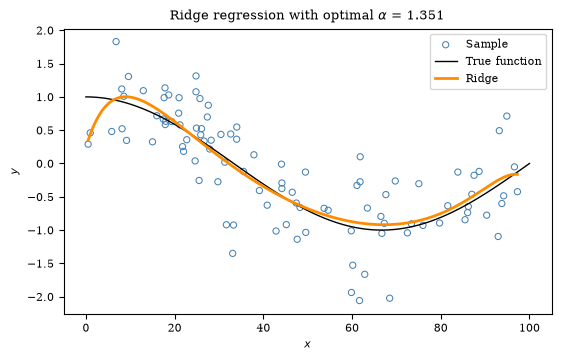

In [21]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Plot predicted values from cross-validated Ridge regression
ax.plot(xvalues, yhat_grid_ridge, c='darkorange', lw=2.0, label='Ridge')

ax.set_title(rf'Ridge regression with optimal $\alpha$ = {alpha_best:.4g}')
_ = ax.legend()

As the figure shows, the optimally selected Ridge model is smoother than the OLS model
and follows the true relationship more closely, except at the left boundary of the
training sample where we have few observations.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Repeat the OLS and Ridge analysis with `N=200`. How do the predictions change?
2. What happens to the selected $\alpha$? Also compare
    $\alpha/N$: dividing Ridge's objective by $N$ gives mean squared error plus a penalty
    with weight $\alpha/N$. This helps us compare penalty strengths across sample sizes.

Restore `N=100` and rerun the analysis before continuing.

</div>
<span style="display: none;">YourTurnEnd</span>

### Dedicated cross-validation with `RidgeCV`

The dedicated
[`RidgeCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html)
class is useful when the input features are already on suitable scales without
learning preprocessing from the current sample. With its default `cv=None`, it
uses an efficient calculation of leave-one-out errors, avoiding a separate model
fit for each omitted observation.

For a short illustration, we center and scale $x$ by the known mean of 50 and upper
bound of 100 before creating polynomial features. Knowing the data-generating process
gives us a natural choice of fixed centering and scaling constants. In applications,
suitable values may be less obvious.
This fixed conversion uses no sample means or standard
deviations, so it can be done before cross-validation. This illustration uses
centered powers of $z = (x-50)/100$ without either learned scaler. Both the polynomial
basis and its scales differ from our main pipeline, so its fitted model and
selected $\alpha$ are not directly comparable. For our main model with learned
standardization, we keep the `GridSearchCV` approach.

We pass candidate values through `alphas` and recover the selected value from
`alpha_`.

In [22]:
from sklearn.linear_model import RidgeCV

# Fixed feature construction; no scales are estimated from the sample
poly = PolynomialFeatures(degree=DEGREE, include_bias=False)
X_train_fixed = poly.fit_transform((X_train - 50) / 100)

# Candidate strengths for these fixed feature scales
ridge_alphas_dedicated = np.logspace(-5, 2, num=200)

# Create a RidgeCV object with candidate alphas
ridge_cv_dedicated = RidgeCV(alphas=ridge_alphas_dedicated)

# Run the cross-validation
ridge_cv_dedicated.fit(X_train_fixed, y_train)

print(f'RidgeCV selected alpha: {ridge_cv_dedicated.alpha_:.4g}')

RidgeCV selected alpha: 0.0003002


The selected $\alpha$ is *not directly comparable* to the earlier pipeline
value because the polynomial basis and feature scales differ.

***
## Lasso

Another widely used estimator with shrinkage is Lasso (least absolute shrinkage and
selection operator). Its objective combines a scaled squared-error
term with an L1 penalty,
$$
L(\mu, \bm{\beta}) =
    \underbrace{\frac{1}{2N}\sum_{i=1}^N \Bigl(
    y_i - \mu - \mathbf{x}_i'\bm{\beta}\Bigr)^2}_{\text{Half the mean squared error}}
    +
    \underbrace{\alpha \sum_{k=1}^K |\beta_k|}_{\text{L1 penalty}}
$$
where we have used the formulation implemented in scikit-learn. You might see slightly different 
but equivalent formulations in other textbooks. 
As with Ridge regression, the additional term penalizes large coefficient values,
while the intercept is not penalized. This term is called an L1 penalty because it
corresponds to the L1 vector norm, which we can also write as
$\alpha \|\bm{\beta}\|_1$.

Using the L1 instead of the squared L2 norm can produce much more parsimonious models:
many coefficients can be exactly zero, eliminating the corresponding features from
the model. We will see this in the example below.

### Estimating the Lasso and linear regression models

We apply Lasso to the same training sample, `X_train` and `y_train`, that we
used for Ridge. This allows us to compare the two methods.

As with Ridge, we standardize the input before creating polynomial features,
then standardize the expanded columns before fitting Lasso. We use the
[`Lasso`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) class
to perform the model estimation. For now, we set the regularization strength to
$\alpha = 0.0075$ and use cross-validation to find the optimal value later.

For Lasso, we may need to increase `max_iter` from its default of 1,000.
We also set `tol=1e-6`, a smaller stopping tolerance than the default of `1e-4`,
to obtain more accurate solutions with our correlated polynomial features.

In [23]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Penalty strength to use for Lasso
alpha = 0.0075

# Build pipeline of transformations and Lasso estimation.
# We create the polynomial transformation w/o the intercept so we
# need to include an intercept in the fitting step.
pipe_lasso = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    Lasso(alpha=alpha, fit_intercept=True, max_iter=10_000, tol=1e-6),
)

pipe_lasso.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](1,)",[45.35]


For comparison, we reuse the fitted OLS pipeline `pipe_ols` and its grid
predictions `yhat_grid_ols` from the Ridge section.

The following code plots the sample data, the true functional relationship, and the predictions from the linear regression and Lasso models.

In [24]:
# Grid predictions from the illustrative Lasso model
yhat_grid_lasso = pipe_lasso.predict(X_grid)

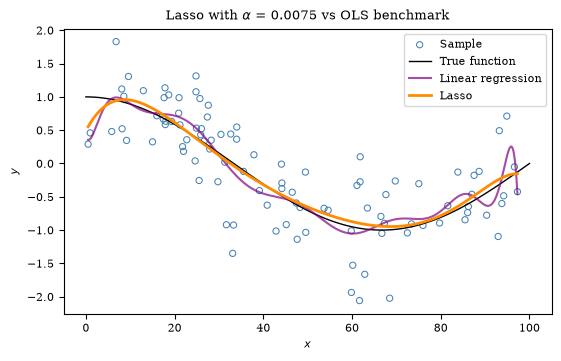

In [25]:
ax = plot_trig_sample(x_train, y_train)

# Linear regression prediction
ax.plot(xvalues, yhat_grid_ols, c='purple', alpha=0.7, label='Linear regression')

# Lasso prediction
ax.plot(xvalues, yhat_grid_lasso, c='darkorange', lw=2.0, label='Lasso')

ax.set_title(rf'Lasso with $\alpha$ = {alpha:.4g} vs OLS benchmark')
_ = ax.legend()

We chose $\alpha = 0.0075$ for this illustration, whereas we initially used
$\alpha = 3$ for Ridge regression. These values are not directly comparable:
scikit-learn divides the squared-error term by $2N$ for Lasso, and the two methods
also use different penalties. There is no general conversion that gives equivalent
shrinkage for Ridge and Lasso. We therefore tune $\alpha$ separately for each model.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Set `alpha=1` in the Lasso setup and rerun the fit and prediction plot. How does the
fitted curve change? Explain the intuition behind this result.

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Lasso path

As for Ridge regression, we can visualize how the estimated Lasso coefficients change as we vary the penalty parameter. This plot is called the *Lasso path*.

To compute the path, we fit the model for different values of $\alpha$ on the
interval $[10^{-4}, 1]$, where we again space $\alpha$ uniformly on a logarithmic
scale. This range includes smaller penalties that can retain more polynomial
features.

We reuse the Lasso pipeline defined above. As in the Ridge path, we update
`lasso__alpha` with `set_params()`, refit the complete pipeline on `X_train`,
and recover the coefficients from `named_steps['lasso']`. The preprocessing
steps are refitted for each value of $\alpha$, using the same training sample.

In [26]:
# Create grid of alphas spaced uniformly in logs on [1e-4, 1]
alphas = np.logspace(start=np.log10(1.0e-4), stop=np.log10(1.0), num=200)

# Allow more iterations and reuse intermediate calculations within each fit
pipe_lasso.set_params(lasso__max_iter=20_000_000, lasso__precompute=True)

# Array to store one coefficient for each polynomial feature and alpha
coefs = np.empty((len(alphas), DEGREE))

# Reuse the Lasso pipeline, updating alpha before each fit
for i, alpha in enumerate(alphas):
    # Update the penalty in the Lasso step
    pipe_lasso.set_params(lasso__alpha=alpha)

    # Refit the pipeline on the original input
    pipe_lasso.fit(X_train, y_train)

    # Store the coefficients for this alpha
    coefs[i] = pipe_lasso.named_steps['lasso'].coef_

We reuse `plot_coefficient_path()` to plot the fitted Lasso coefficients against
$\alpha$ on a log scale:

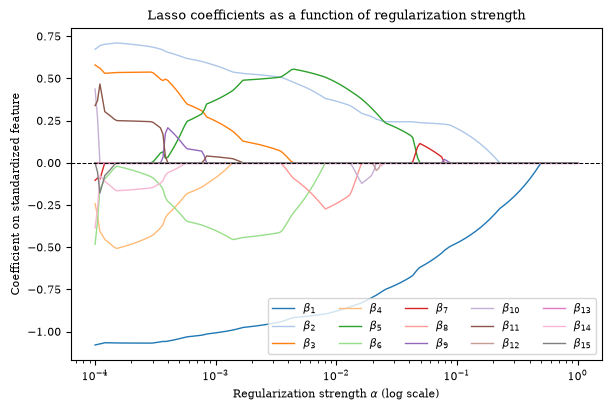

In [27]:
import matplotlib.pyplot as plt

plot_coefficient_path(alphas, coefs, 'Lasso')

The coefficient paths differ from those obtained with Ridge. For sufficiently
large $\alpha$, many Lasso coefficients are exactly zero. We highlight this
result in the graph below, which plots the number of nonzero coefficients
against $\alpha$.

In [28]:
# Treat very small coefficient values as zero
nonzero = np.sum(np.abs(coefs) > 1.0e-6, axis=1)

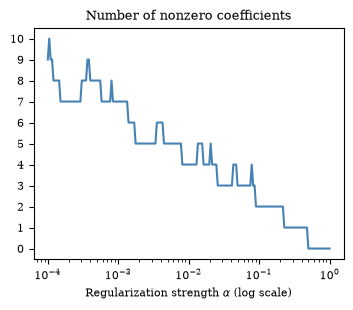

In [29]:
# Plot number of nonzero coefficients against alpha
plt.plot(alphas, nonzero, lw=1.5, c='steelblue')
plt.xscale('log', base=10)
plt.yticks(np.arange(0, np.amax(nonzero) + 1))
plt.xlabel(r'Regularization strength $\alpha$ (log scale)')
_ = plt.title('Number of nonzero coefficients')

At small values of $\alpha$, Lasso retains more of the 15 polynomial features.
As the penalty increases, we generally obtain models with fewer nonzero coefficients,
eventually leaving only the intercept.

It's important to stress that we fit Lasso on standardized polynomial features. 
Our pipeline first
centers and scales $x$ to obtain $z$, then creates $z, z^2, \ldots, z^{15}$.
The second scaler standardizes each of these polynomial columns before fitting
Lasso, putting them on comparable scales for the penalty. A zero coefficient
means that Lasso leaves out one of these *transformed* features.
It does not necessarily mean that Lasso leaves out the corresponding power of the
original input $x$.

We can see why centering matters with a simple example. We temporarily ignore
scaling and write $z = x - 5$. Suppose our fitted model retains only the $z^2$
feature. Rewriting this feature gives
$$
z^2 = (x - 5)^2 = x^2 - 10x + 25.
$$
The same fitted curve therefore contains both an $x^2$ term and an $x$ term when
written in terms of the original input, with the constant absorbed into the
intercept. Standardizing the $z^2$ column changes its scale and shifts its
constant term, but it still involves both powers of $x$.

The practical implication is that the number of nonzero coefficients describes
how many features we retain from our chosen polynomial expansion. We cannot
interpret a zero coefficient on the standardized $z$ feature as evidence that
the fitted curve has no $x$ term.

Changing the center before fitting can also change the fitted curve: it changes
the polynomial features and the coefficients that Lasso penalizes. Standardizing
the columns makes their scales comparable, but does not make these different
expansions equivalent under the Lasso penalty. Our pipeline is appropriate for
this prediction example; we use cross-validation to select its penalty strength.
If we also want to choose between different centering or feature-construction
methods, we should compare those choices using cross-validation as well.

We can also compute the Lasso path using the convenience function
[`lasso_path()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.lasso_path.html).
This function takes a feature matrix directly, so we prepare the standardized
polynomial features ourselves. It does not fit an intercept, so we also subtract
the mean of $y$. Here we are illustrating fitted coefficients on one sample, rather
than estimating validation performance.

In [30]:
from sklearn.linear_model import lasso_path

# Re-create pipeline w/o Lasso estimator to be used with lasso_path()
transform = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
)

# Create polynomial features
X_train_trans = transform.fit_transform(X_train)

# Center the training target because lasso_path does not fit an intercept
y_train_centered = y_train - np.mean(y_train)

# Compute Lasso path automatically
alphas, coefs, _ = lasso_path(
    X_train_trans, y_train_centered, alphas=alphas, max_iter=20_000_000, tol=1e-6
)

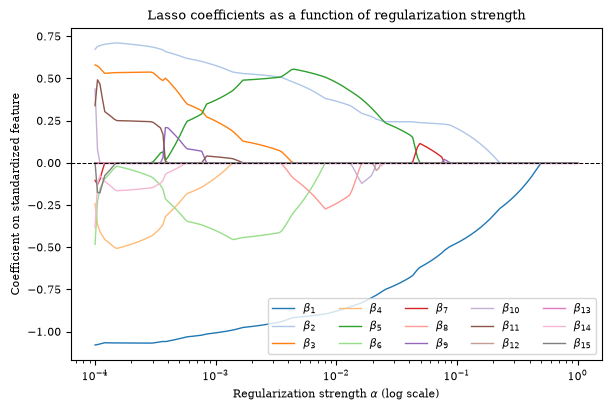

In [31]:
# Transpose so each row contains the coefficients for one alpha
plot_coefficient_path(alphas, coefs.T, 'Lasso')

The two paths can differ because the numerical algorithm stops once it reaches a
specified tolerance. Our loop fits each model from scratch, while `lasso_path()`
starts each fit from the solution for a nearby $\alpha$. Reusing a previous solution
is called a *warm start* and often saves computation. With highly correlated
polynomial features, these choices can produce visible differences in coefficients.
More iterations and a smaller `tol` can improve agreement, at the cost of more
computation.

***
### Tuning the regularization parameter via cross-validation

We now select $\alpha$ for Lasso using
[`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
As in the Ridge example, the search wraps the complete pipeline so that both
scalers are learned separately within each training fold.
Scikit-learn also provides a dedicated
[`LassoCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html)
class that selects $\alpha$ by cross-validation. However, it does not refit
scalers within its internal folds, and thus may suffer from the same data-leakage issue as `RidgeCV`. 
We therefore use `GridSearchCV`
around the complete pipeline here and discuss the `LassoCV` alternative below.

We search from $10^{-4}$ to $10^{-1}$ using the same five folds and negative
MSE scoring rule as before. Including smaller penalties lets us compare sparse
models with models that retain more of the expansion.

We allow more iterations for the highly correlated polynomial features and keep
`tol=1e-6`. Setting `precompute=True` computes a matrix of feature cross-products
once per fit and reuses it during the solver's iterations. Each fit performed by
`GridSearchCV` computes its own matrix.

In [32]:
# Candidate regularization strengths for Lasso
lasso_alphas = np.logspace(-4, -1, num=200)

# Keep all preprocessing inside the pipeline
pipe_lasso = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    Lasso(max_iter=20_000_000, tol=1e-6, precompute=True),
)

# Define the grid search for Lasso regression with cross-validation
lasso_cv = GridSearchCV(
    pipe_lasso,
    param_grid={'lasso__alpha': lasso_alphas},  # parameters to search over
    scoring=scoring,  # scoring metric for cross-validation
    cv=cv,  # CV splitting strategy
    refit=True,  # refit the best model on the entire training set
    n_jobs=4,  # parallelize over 4 CPU cores
)

# Run the cross-validation
lasso_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... tol=1e-06))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lasso__alpha': array([0.0001..., 0.1 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls

We recover the selected $\alpha$ from `best_params_` and the validation
scores from `cv_results_`, just as we did for Ridge.

In [33]:
# Optimal alpha of the best model
alpha_best = lasso_cv.best_params_['lasso__alpha']

# Average validation MSE of the best model
mse_lasso_cv = -lasso_cv.best_score_

print(f'Best alpha: {alpha_best:.4g}')
print(f'CV MSE: {mse_lasso_cv:.4g}')

Best alpha: 0.005053
CV MSE: 0.2487


The selected pipeline is stored in `best_estimator_`. We access its fitted
Lasso step through `named_steps['lasso']` and count the nonzero coefficients.
As in the path plot, we treat absolute values at or below $10^{-6}$ as zero.

In [34]:
# Reference to best Lasso estimator
lasso_best = lasso_cv.best_estimator_.named_steps['lasso']

# Count the number of nonzero coefficients in the best Lasso model
n_features = np.sum(np.abs(lasso_best.coef_) > 1.0e-6)
print(f'Number of nonzero coefficients: {n_features}')

Number of nonzero coefficients: 5


For our demo sample, cross-validation selects $\alpha \approx 0.00505$ with
a CV MSE of about 0.249. The refitted model retains 5 of the 15 polynomial
features. Thus, Lasso reduces the number of features, although its sparsity
depends on the input transformation and the penalty chosen by cross-validation.

We reuse `plot_validation_curve()` with the fitted Lasso search to show average
validation MSE across the candidate values of $\alpha$. If a selected value is
at an endpoint of the grid, we would expand the grid to check whether values
beyond it perform better.

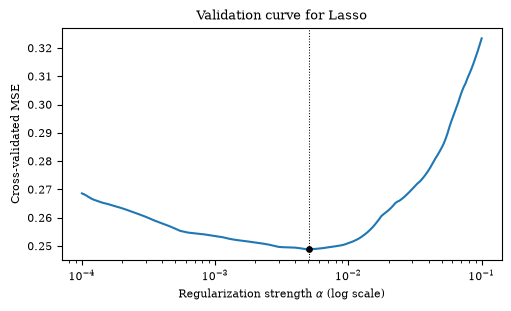

In [35]:
plot_validation_curve(lasso_cv, 'Lasso')

The search has already refitted the selected pipeline on the full training sample.
We use this best model to predict `yhat_grid_lasso` on
the prediction grid.

In [36]:
# Recover the pipeline already fitted with the selected alpha
pipe_lasso = lasso_cv.best_estimator_

# Compute grid predictions using the selected Lasso model
yhat_grid_lasso = pipe_lasso.predict(X_grid)

Finally, we visually compare the true model to the Lasso prediction using the optimal value of $\alpha$.

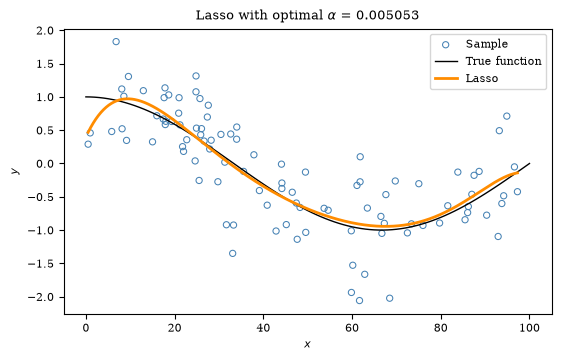

In [37]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Plot prediction from optimal Lasso model
ax.plot(xvalues, yhat_grid_lasso, c='darkorange', lw=2.0, label=r'Lasso')

ax.set_title(rf'Lasso with optimal $\alpha$ = {alpha_best:.4g}')
_ = ax.legend()

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Perform the following tasks using the fitted Lasso model `pipe_lasso`:

- Compute the training MSE using the predicted values `pipe_lasso.predict(X_train)` and `y_train`.

    *Hint:* You can use
    [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html)
    from `sklearn.metrics` to compute the MSE.

- Compare the training MSE with the CV MSE stored in `mse_lasso_cv`. Which is lower
  for this sample? What could explain the difference?

</div>
<span style="display: none;">YourTurnEnd</span>

### Dedicated cross-validation with `LassoCV`

The dedicated
[`LassoCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html)
class is useful when no preprocessing needs to be learned within the folds. It can
be faster than a general grid search because it reuses the coefficients from a
nearby $\alpha$ as a starting point for the next fit. We encountered this idea of
warm starts in the Lasso path example.

As in the `RidgeCV` illustration, we center and scale $x$ using its known mean of
50 and upper bound of 100, then construct polynomial features from
$z = (x-50)/100$. We do not fit a scaler on the full sample.
This illustration uses centered powers of $z$ without either learned scaler.
Its polynomial basis and feature scales differ from our main example;
we use this calculation only to illustrate the dedicated class.

We supply the candidate grid and folds through `alphas` and `cv`. The class
selects $\alpha$ using validation MSE and stores it in `alpha_`.

In [38]:
from sklearn.linear_model import LassoCV

# Fixed feature construction; no scales are estimated from the sample
poly = PolynomialFeatures(degree=DEGREE, include_bias=False)
X_train_fixed = poly.fit_transform((X_train - 50) / 100)

# Candidate strengths for these fixed feature scales
lasso_alphas_dedicated = np.logspace(-5, -2, num=200)

# Create a LassoCV object with candidate alphas
lasso_cv_dedicated = LassoCV(alphas=lasso_alphas_dedicated, cv=cv, max_iter=1_000_000)

# Run the cross-validation
lasso_cv_dedicated.fit(X_train_fixed, y_train)

print(f'LassoCV selected alpha: {lasso_cv_dedicated.alpha_:.4g}')

LassoCV selected alpha: 7.233e-05


We obtain a much smaller $\alpha \approx 7.2 \times 10^{-5}$ than in the
standardized pipeline ($\alpha \approx 0.0051$), but these values are not directly
comparable because the polynomial basis and feature scales differ.

***
## Elastic Net

Elastic Net is a regularized linear regression model that combines the L1 and L2
penalties of Lasso and Ridge. Its objective, using the scikit-learn formulation, is:
$$
L(\mu, \bm{\beta}) =
    \underbrace{\frac{1}{2N}\sum_{i=1}^N \Bigl(
    y_i - \mu - \mathbf{x}_i'\bm{\beta}\Bigr)^2}_{\text{Half the mean squared error}}
    +
    \underbrace{\alpha \rho \sum_{k=1}^K |\beta_k|}_{\text{L1 penalty}}
    +
    \underbrace{\frac{\alpha (1-\rho)}{2}
    \sum_{k=1}^K\beta_k^2}_{\text{L2 penalty}}
$$
As before, the intercept is not penalized.

By incorporating both penalties, Elastic Net can produce a sparse model with many
zero coefficients while also using Ridge's squared-coefficient penalty. The
hyperparameter $\rho \in [0, 1]$, called `l1_ratio` in scikit-learn, controls the
mix of the two penalties:

- When $\rho = 1$, the model is equivalent to Lasso with the same $\alpha$.
- When $\rho = 0$, only the L2 penalty remains. This gives a Ridge model, but the
  different scaling of the objective means that the equivalent Ridge parameter is
  $\alpha_{\text{Ridge}} = N \cdot \alpha_{\text{Elastic Net}}$.

### Estimating the Elastic Net and linear regression models

We use the same training sample, `X_train` and `y_train`, from the previous
sections to fit the Elastic Net model.

We first illustrate the estimation for a fixed set of hyperparameters:
`alpha = 0.01` and `l1_ratio = 0.5` (an equal mix of L1 and L2 penalties).
For comparison, we reuse the OLS pipeline `pipe_ols` from the earlier
[`LinearRegression()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
fit. It already uses the same training sample and polynomial features.

As with Lasso earlier, it may be necessary to increase `max_iter` to ensure convergence. 

In [39]:
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Build pipeline for Elastic Net
pipe_enet = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    ElasticNet(
        alpha=0.01, l1_ratio=0.5, fit_intercept=True, max_iter=100_000, tol=1e-6
    ),
)

# Fit Elastic Net
pipe_enet.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](1,)",[45.35]


We now compare the predicted values from both models against the true underlying function.

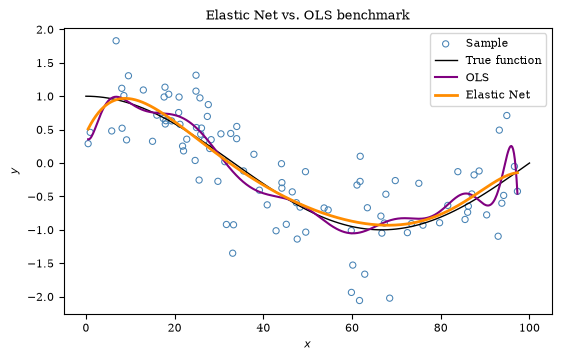

In [40]:
# Grid predictions from the illustrative Elastic Net model
yhat_grid_enet = pipe_enet.predict(X_grid)

# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Plot predictions
ax.plot(xvalues, yhat_grid_ols, c='purple', lw=1.5, ls='-', label='OLS')
ax.plot(xvalues, yhat_grid_enet, c='darkorange', lw=2.0, label='Elastic Net')

ax.set_title(r'Elastic Net vs. OLS benchmark')
_ = ax.legend()

### Tuning the regularization parameters via cross-validation

Unlike Ridge and Lasso, Elastic Net has two hyperparameters to tune: $\alpha$ and
the L1 ratio $\rho$. We use
[`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
to try every combination of 200 candidate values of $\alpha$ and six L1 ratios.
We search from $10^{-4}$ to $10^{-1}$ for $\alpha$ and include small L1 ratios
to explore solutions close to Ridge.

The search again wraps the entire pipeline so that both scalers are fitted
within each training fold. The dedicated
[`ElasticNetCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNetCV.html)
class has the same data leakage issue if we preprocess the full sample before
its internal splits.
We keep the same five folds and scoring rule as in the other examples.

In [41]:
# Candidate values for both hyperparameters
l1_ratios = [0.001, 0.01, 0.1, 0.5, 0.9, 0.95]
enet_alphas = np.logspace(-4, -1, num=200)

# Keep all preprocessing inside the pipeline
pipe_enet = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=DEGREE, include_bias=False),
    StandardScaler(),
    ElasticNet(max_iter=20_000_000, tol=1e-6, precompute=True),
)

# Define the parameter grid for the Elastic Net search
param_grid = {
    'elasticnet__alpha': enet_alphas,
    'elasticnet__l1_ratio': l1_ratios,
}

# Define the grid search for Elastic Net regression with cross-validation
enet_cv = GridSearchCV(
    pipe_enet,
    param_grid=param_grid, # parameters to search over
    scoring=scoring, # scoring metric for cross-validation
    cv=cv, # CV splitting strategy
    refit=True, # refit the best model on the entire training set
    n_jobs=4, # parallelize over 4 CPU cores
)

# Run the cross-validation
enet_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... tol=1e-06))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'elasticnet__alpha': array([0.0001..., 0.1 ]), 'elasticnet__l1_ratio': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added

We allow more iterations than the default of 1,000 and set `tol=1e-6` because
these polynomial features are highly correlated. Setting `precompute=True`
also speeds up fitting by reusing intermediate calculations within each fit.
If fitting produces a `ConvergenceWarning`, we need to check the affected fits
before relying on the search results. A larger `max_iter` allows more work
but does not guarantee convergence.

Once the cross-validation is completed, we can access the selected hyperparameters through `best_params_` and the average validation score through `best_score_`:

In [42]:
# Optimal alpha of the best model
alpha_best = enet_cv.best_params_['elasticnet__alpha']

# Optimal L1 ratio of the best model
l1_ratio_best = enet_cv.best_params_['elasticnet__l1_ratio']

# Average validation MSE of the best model
mse_enet_cv = -enet_cv.best_score_

print(f'Best alpha: {alpha_best:.4g}')
print(f'Best L1 ratio: {l1_ratio_best:.4g}')
print(f'CV MSE: {mse_enet_cv:.4g}')

Best alpha: 0.01534
Best L1 ratio: 0.1
CV MSE: 0.2483


For our demo sample, the search selects $\alpha \approx 0.0153$ and
$\rho = 0.1$, with a CV MSE of about 0.248.

A small selected L1 ratio puts most weight on the L2 part of the penalty.
Such an Elastic Net model can retain many or all of the features, much like
Ridge. A ratio close to one favors Lasso's L1 penalty and can produce a sparser
model. We therefore cannot assume that Elastic Net will select only a few
features in every sample.

The search has already refitted the selected pipeline on the full training sample.
We use this best model to predict `yhat_grid_enet` on
the prediction grid.

In [43]:
# Recover the pipeline already fitted with the selected hyperparameters
pipe_enet = enet_cv.best_estimator_

# Compute grid predictions using the selected Elastic Net model
yhat_grid_enet = pipe_enet.predict(X_grid)

Finally, we visually compare the true model to the Elastic Net prediction using
the optimal values of $\alpha$ and $\rho$.

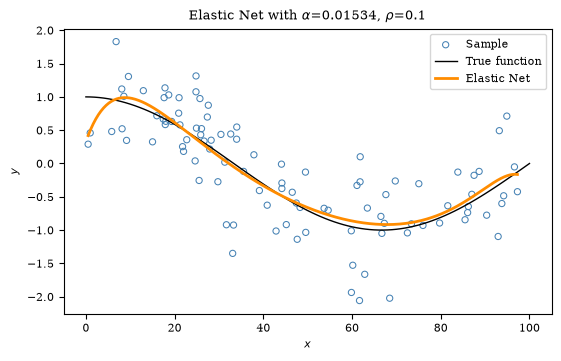

In [44]:
# Plot sample and true relationship
ax = plot_trig_sample(x_train, y_train)

# Plot prediction from optimal Elastic Net model
ax.plot(xvalues, yhat_grid_enet, c='darkorange', lw=2.0, label='Elastic Net')

title = rf'Elastic Net with $\alpha$={alpha_best:.4g}, $\rho$={l1_ratio_best:.4g}'
ax.set_title(title)
_ = ax.legend()

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Using the code from above, perform the following tasks:

- Count the nonzero coefficients in the selected Elastic Net model, using the same
  $10^{-6}$ threshold as for Lasso. How many additional features does Elastic Net retain?
- Compare the CV MSEs of the two models. Is the improvement from Elastic Net substantial?

*Hint:* The Elastic Net coefficients are in
`enet_cv.best_estimator_.named_steps['elasticnet'].coef_`. For Lasso, reuse
`n_features`. The CV MSEs are `mse_enet_cv` and `mse_lasso_cv`.

</div>
<span style="display: none;">YourTurnEnd</span>

### Dedicated cross-validation with `ElasticNetCV`

The dedicated
[`ElasticNetCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNetCV.html)
class searches over both $\alpha$ and the L1 ratio. Like `LassoCV`, it reuses
solutions along the regularization path, which can make tuning faster than fitting
each candidate independently. It is useful when the input features require no
preprocessing learned within each fold. It does not solve the leakage problem for a
scaler placed before it in a pipeline.

As in the `LassoCV` illustration, we use fixed, centered powers of
$z = (x-50)/100$ and no learned scalers. These features differ from those in our
main pipeline. We recover the selected parameters from `alpha_` and `l1_ratio_`.

In [45]:
from sklearn.linear_model import ElasticNetCV

# Fixed feature construction; no scales are estimated from the sample
poly = PolynomialFeatures(degree=DEGREE, include_bias=False)
X_train_fixed = poly.fit_transform((X_train - 50) / 100)

# Candidate strengths for these fixed feature scales
enet_alphas_dedicated = np.logspace(-6, -2, num=200)

# Candidate L1 ratios for Elastic Net
l1_ratios_dedicated = [1.0e-6, 0.001, 0.01, 0.1, 0.5, 0.9, 0.95]

# Create an ElasticNetCV object with candidate alphas and L1 ratios
enet_cv_dedicated = ElasticNetCV(
    alphas=enet_alphas_dedicated,
    l1_ratio=l1_ratios_dedicated,
    cv=cv,
    max_iter=5_000_000,
    tol=1e-6,
    precompute=True,
    n_jobs=4,
)

# Run the cross-validation
enet_cv_dedicated.fit(X_train_fixed, y_train)

print(f'ElasticNetCV selected alpha: {enet_cv_dedicated.alpha_:.4g}')
print(f'ElasticNetCV selected L1 ratio: {enet_cv_dedicated.l1_ratio_:.4g}')

ElasticNetCV selected alpha: 8.407e-06
ElasticNetCV selected L1 ratio: 1e-06


We are fitting substantially different regularized models because the polynomial
basis and feature scales change the meaning of the penalty, so the selected
$\alpha$ and L1 ratio are not directly comparable to those from our standardized
pipeline.

The selected L1 ratio is close to zero, suggesting that cross-validation favors
an almost pure Ridge penalty for these features; repeatedly lowering the grid
boundary adds little practical information.

***
## Comparing predictions on new observations

The minimum CV MSE helped us choose hyperparameters. To assess the resulting models,
we now generate a large test sample of 100,000 observations that played no part in
fitting or tuning. A new random generator gives us independent observations from the
same model. The large sample makes the comparison less sensitive to chance variation
in the test observations. We use the fitted pipelines without refitting or tuning
them on this test sample.

We compute prediction errors with
[`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html)
and compare predictions with the noisy test outcomes `y_test`. Even the true cosine
function would have an expected MSE of $0.5^2 = 0.25$ because of the measurement
error. This gives us a useful benchmark when interpreting the results.

In [46]:
from sklearn.metrics import mean_squared_error

# Generate a large independent test sample
x_test, y_test = create_trig_sample(N=100_000, rng=default_rng(5678))
X_test = x_test[:, None]

# Predictions from OLS and the selected regularized models
yhat_test_ols = pipe_ols.predict(X_test)
yhat_test_ridge = pipe_ridge.predict(X_test)
yhat_test_lasso = pipe_lasso.predict(X_test)
yhat_test_enet = pipe_enet.predict(X_test)

# Compute the OLS benchmark for the relative comparison
mse_ols_test = mean_squared_error(y_test, yhat_test_ols)

The following code reports the results.
The table includes the CV MSE from each regularized model's pipeline search;
we show a dash for OLS because we did not cross-validate it.
For each model, we also report the percentage reduction in test MSE relative to OLS.
A positive reduction means better prediction than OLS. This comparison evaluates the
models fitted on our particular training sample; a different training sample could
change the results.



In [47]:
predictions = [
    ('OLS', yhat_test_ols, None),
    ('Ridge', yhat_test_ridge, mse_ridge_cv),
    ('Lasso', yhat_test_lasso, mse_lasso_cv),
    ('Elastic Net', yhat_test_enet, mse_enet_cv),
]

print(f'{"Model":<12} {"CV MSE":>8} {"Test MSE":>10} {"Reduction vs OLS":>17}')
for name, yhat_test, mse_cv in predictions:
    mse_test = mean_squared_error(y_test, yhat_test)
    reduction = (mse_ols_test - mse_test) / mse_ols_test

    # OLS was not cross-validated in this example
    cv_text = '-' if mse_cv is None else f'{mse_cv:.5f}'

    print(f'{name:<12} {cv_text:>8} {mse_test:10.5f} {reduction:17.2%}')

Model          CV MSE   Test MSE  Reduction vs OLS
OLS                 -    1.32244             0.00%
Ridge         0.24892    0.26217            80.17%
Lasso         0.24874    0.25870            80.44%
Elastic Net   0.24826    0.26058            80.30%


The test MSE is about 1.322 for OLS, 0.262
for Ridge, 0.259 for Lasso, and 0.261 for Elastic Net. All three regularized
models reduce test MSE by about 80% relative to OLS, with errors close to the
noise benchmark of 0.25.
The large OLS error is mostly driven by predictions near the upper end of
$[0, 100]$, beyond the largest training value of about 97.3. Our prediction
plots stop at the largest training value, so they do not show these extreme
predictions.

These results illustrate the benefits of regularization for our fitted
degree-15 polynomial; they do not establish that one method always predicts
better than the others.
Elastic Net achieves the lowest CV MSE but a slightly higher test MSE than Lasso,
while all three regularized models perform similarly on this sample.

***
## List of functions used in this lecture

The following list contains the central functions covered in this lecture. Each function
name is linked to the official API documentation which you can consult for more details
regarding function arguments and return values. The `[[go to section]]` links take us to
the relevant sections in this notebook.

### NumPy array functions

- [`logspace()`](https://numpy.org/doc/stable/reference/generated/numpy.logspace.html): Function for creating numbers spaced evenly on a log scale. [[go to section]](#Ridge-path)

### scikit-learn model selection

- [`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html): Cross-validation over a parameter grid for a complete pipeline. [[go to section]](#Tuning-the-regularization-parameter-via-cross-validation)
- [`KFold()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html): Split observations into training and validation folds. [[go to section]](#Tuning-the-regularization-parameter-via-cross-validation)

### scikit-learn metrics

- [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html): Average squared prediction error. [[go to section]](#Comparing-predictions-on-new-observations)

### scikit-learn linear models

- [`Ridge()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html): Linear least squares with L2 regularization. [[go to section]](#Estimating-the-Ridge-model)
- [`RidgeCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html): Ridge regression with built-in cross-validation. [[go to section]](#Dedicated-cross-validation-with-RidgeCV)
- [`Lasso()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html): Linear model with L1 regularization (shrinkage). [[go to section]](#Estimating-the-Lasso-and-linear-regression-models)
- [`lasso_path()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.lasso_path.html): Function for computing the Lasso path with coordinate descent. [[go to section]](#Lasso-path)
- [`LassoCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html): Lasso linear model with iterative fitting along a regularization path. [[go to section]](#Dedicated-cross-validation-with-LassoCV)
- [`ElasticNet()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html): Linear regression with combined L1 and L2 priors as regularizer. [[go to section]](#Estimating-the-Elastic-Net-and-linear-regression-models)
- [`ElasticNetCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNetCV.html): Elastic Net model with iterative fitting along a regularization path. [[go to section]](#Dedicated-cross-validation-with-ElasticNetCV)